# TF-IDF (Term Frequency - Inverse Document Frequency)

Metin madenciliği ve bilgi erişiminde kullanılan, bir terimin (kelimenin) bir doküman içindeki önemini ölçen istatistiksel bir yöntemdir.

## 1. Bileşenler

### TF (Term Frequency) – Terim Sıklığı
Bir terimin bir dokümanda ne sıklıkta geçtiğini gösterir.

$$\text{TF}(t,d) = \frac{\text{terimin dokümanda geçme sayısı}}{\text{dokümandaki toplam terim sayısı}}$$

### IDF (Inverse Document Frequency) – Ters Doküman Sıklığı
Bir terimin tüm dokümanlarda ne kadar nadir geçtiğini ölçer.

$$\text{IDF}(t) = \log\left(\frac{\text{toplam doküman sayısı}}{\text{terimi içeren doküman sayısı}}\right)$$

### TF-IDF
TF ve IDF değerlerinin çarpımıdır:

$$\text{TF-IDF}(t,d) = \text{TF}(t,d) \times \text{IDF}(t)$$

## 2. Temel Python Uygulaması

In [1]:
import math
import sys
import warnings
warnings.filterwarnings('ignore')

kucuk_dokumanlar = [
    "kedi evde uyuyor",
    "köpek parkta koşuyor",
    "kedi ve köpek birlikte oynuyor",
    "evde kedi maması var",
]

def tokenize(text):
    return text.lower().split()

tokenize_kucuk = [tokenize(d) for d in kucuk_dokumanlar]
print("Tokenize edilmiş dokümanlar:")
for i, d in enumerate(tokenize_kucuk):
    print(f"  Doküman {i+1}: {d}")

Tokenize edilmiş dokümanlar:
  Doküman 1: ['kedi', 'evde', 'uyuyor']
  Doküman 2: ['köpek', 'parkta', 'koşuyor']
  Doküman 3: ['kedi', 've', 'köpek', 'birlikte', 'oynuyor']
  Doküman 4: ['evde', 'kedi', 'maması', 'var']


In [2]:
def tf(term, tokenize_doc):
    count = tokenize_doc.count(term)
    return count / len(tokenize_doc) if len(tokenize_doc) > 0 else 0

def idf(term, tokenize_dokumanlar):
    doc_count = sum(1 for doc in tokenize_dokumanlar if term in doc)
    return math.log(len(tokenize_dokumanlar) / (1 + doc_count)) + 1

print("TF-IDF Değerleri:\n")
for i, doc in enumerate(tokenize_kucuk):
    print(f"--- Doküman {i+1}: '{kucuk_dokumanlar[i]}' ---")
    for term in sorted(set(doc)):
        tf_val = tf(term, doc)
        idf_val = idf(term, tokenize_kucuk)
        tfidf_val = tf_val * idf_val
        print(f"  '{term}' -> TF: {tf_val:.4f}, IDF: {idf_val:.4f}, TF-IDF: {tfidf_val:.4f}")
    print()

TF-IDF Değerleri:

--- Doküman 1: 'kedi evde uyuyor' ---
  'evde' -> TF: 0.3333, IDF: 1.2877, TF-IDF: 0.4292
  'kedi' -> TF: 0.3333, IDF: 1.0000, TF-IDF: 0.3333
  'uyuyor' -> TF: 0.3333, IDF: 1.6931, TF-IDF: 0.5644

--- Doküman 2: 'köpek parkta koşuyor' ---
  'koşuyor' -> TF: 0.3333, IDF: 1.6931, TF-IDF: 0.5644
  'köpek' -> TF: 0.3333, IDF: 1.2877, TF-IDF: 0.4292
  'parkta' -> TF: 0.3333, IDF: 1.6931, TF-IDF: 0.5644

--- Doküman 3: 'kedi ve köpek birlikte oynuyor' ---
  'birlikte' -> TF: 0.2000, IDF: 1.6931, TF-IDF: 0.3386
  'kedi' -> TF: 0.2000, IDF: 1.0000, TF-IDF: 0.2000
  'köpek' -> TF: 0.2000, IDF: 1.2877, TF-IDF: 0.2575
  'oynuyor' -> TF: 0.2000, IDF: 1.6931, TF-IDF: 0.3386
  've' -> TF: 0.2000, IDF: 1.6931, TF-IDF: 0.3386

--- Doküman 4: 'evde kedi maması var' ---
  'evde' -> TF: 0.2500, IDF: 1.2877, TF-IDF: 0.3219
  'kedi' -> TF: 0.2500, IDF: 1.0000, TF-IDF: 0.2500
  'maması' -> TF: 0.2500, IDF: 1.6931, TF-IDF: 0.4233
  'var' -> TF: 0.2500, IDF: 1.6931, TF-IDF: 0.4233



## 3. Scikit-learn ile TF-IDF

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

vectorizer = TfidfVectorizer()
tfidf_matrisi = vectorizer.fit_transform(kucuk_dokumanlar)

df = pd.DataFrame(
    tfidf_matrisi.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=[f"Doküman {i+1}" for i in range(len(kucuk_dokumanlar))]
)
df

,birlikte,evde,kedi,koşuyor,köpek,maması,oynuyor,parkta,uyuyor,var,ve
Doküman 1,0.000000,0.553492,0.448100,0.000000,0.000000,0.00000,0.000000,0.000000,0.702035,0.00000,0.000000
Doküman 2,0.000000,0.000000,0.000000,0.617614,0.486934,0.00000,0.000000,0.617614,0.000000,0.00000,0.000000
Doküman 3,0.498197,0.000000,0.317993,0.000000,0.392784,0.00000,0.498197,0.000000,0.000000,0.00000,0.498197
Doküman 4,0.000000,0.453005,0.366747,0.000000,0.000000,0.57458,0.000000,0.000000,0.000000,0.57458,0.000000


In [4]:
print("Her Dokümanda En Yüksek TF-IDF Skoruna Sahip Kelime:\n")
for i, doc in enumerate(kucuk_dokumanlar):
    satir = df.iloc[i]
    en_iyi = satir.idxmax()
    skor = satir.max()
    print(f"Doküman {i+1}: '{doc}'")
    print(f"  -> En önemli kelime: '{en_iyi}' (skor: {skor:.4f})\n")

Her Dokümanda En Yüksek TF-IDF Skoruna Sahip Kelime:

Doküman 1: 'kedi evde uyuyor'
  -> En önemli kelime: 'uyuyor' (skor: 0.7020)

Doküman 2: 'köpek parkta koşuyor'
  -> En önemli kelime: 'koşuyor' (skor: 0.6176)

Doküman 3: 'kedi ve köpek birlikte oynuyor'
  -> En önemli kelime: 'birlikte' (skor: 0.4982)

Doküman 4: 'evde kedi maması var'
  -> En önemli kelime: 'maması' (skor: 0.5746)



## 4. Görselleştirme

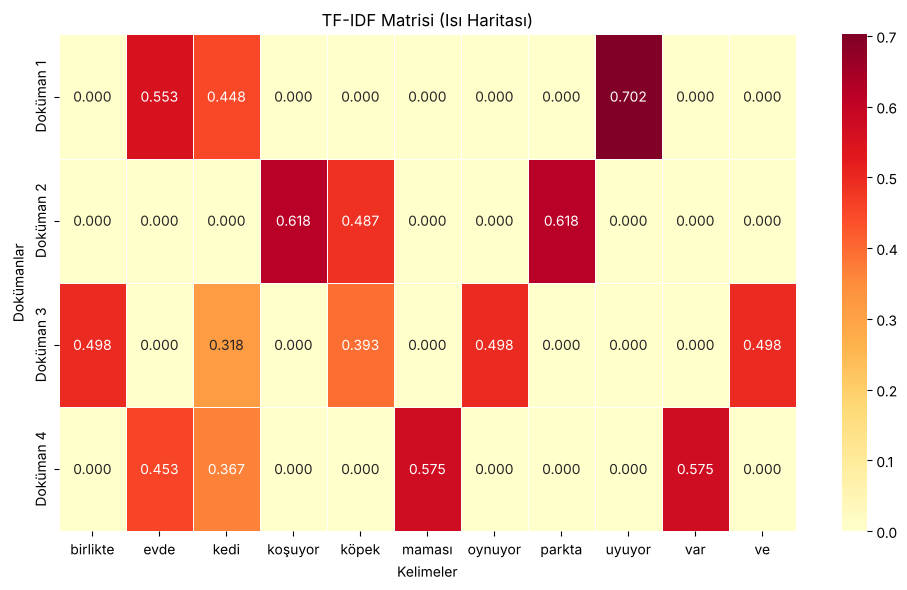

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(df, annot=True, cmap="YlOrRd", fmt=".3f", linewidths=0.5)
plt.title("TF-IDF Matrisi (Isı Haritası)")
plt.xlabel("Kelimeler")
plt.ylabel("Dokümanlar")
plt.tight_layout()
plt.show()

## 5. Özet (Şimdiye Kadar)

- **TF (Term Frequency):** Bir kelimenin dokümanda ne kadar geçtiğini ölçer.
- **IDF (Inverse Document Frequency):** Kelimenin tüm dokümanlarda ne kadar nadir olduğunu ölçer.
- **TF-IDF:** İki değerin çarpımıdır. Bir kelimenin bir doküman için önemini gösterir.
- **Kullanım Alanları:** Metin sınıflandırma, belge benzerliği, arama motorları.

---

# 6. TF-IDF'in Limitlerini Anlamak

TF-IDF basit ve etkili bir yöntemdir ancak bazı temel sınırlamaları vardır. Bu sınırlamaları anlamak, neden daha gelişmiş yöntemlere (Word2Vec, BERT vb.) ihtiyaç duyulduğunu gösterir.

---
## 6.1 Anlamsal İlişki (Semantics)

**Sorun:** TF-IDF her kelimeyi bağımsız bir kimlik (ID) olarak ele alır. "Kral" ile "Kraliçe" arasında semantik bir ilişki olduğunu bilmez. Bunlar sadece farklı sütunlardır.

**Sonuç:** "Kral" ve "Kraliçe" kelimelerinin vektörleri arasındaki benzerlik, "Kral" ile "Masa" arasındaki benzerlikle aynıdır (0).

**Çözüm:** Kelimeleri yoğun (dense) vektörlerde gömülü olarak temsil eden Word2Vec, GloVe gibi yöntemler bu sorunu çözer.

In [6]:
# ÖRNEK: Anlamsal ilişkinin TF-IDF ile yakalanamaması
print("=" * 70)
print("PROBLEM 1: Anlamsal İlişki (Semantics)")
print("=" * 70)

dok_semantik = [
    "kral sarayda yaşar",
    "kraliçe sarayda yaşar",
    "masa odada duruyor",
]

v = TfidfVectorizer()
m = v.fit_transform(dok_semantik)
df_sem = pd.DataFrame(m.toarray(), columns=v.get_feature_names_out(),
                      index=["kral sarayda yaşar", "kraliçe sarayda yaşar", "masa odada duruyor"])

print("\nTF-IDF Vektörleri:")
display(df_sem)

from sklearn.metrics.pairwise import cosine_similarity

benzerlik = cosine_similarity(m[0:1], m[1:3])[0]
print(f"\nKosinüs Benzerlikleri:")
print(f"  'kral ...' vs 'kraliçe ...' : {benzerlik[0]:.4f}")
print(f"  'kral ...' vs 'masa ...'    : {benzerlik[1]:.4f}")
print(f"\nKral-Kraliçe benzerliği ({benzerlik[0]:.4f}) ile Kral-Masa benzerliği ({benzerlik[1]:.4f})")
print(f"neredeyse aynı! Oysa kral ve kraliçe anlamsal olarak çok daha yakın.")
print(f"TF-IDF ortak kelimelere göre benzerlik hesaplar, anlama göre değil.")

PROBLEM 1: Anlamsal İlişki (Semantics)

TF-IDF Vektörleri:


,duruyor,kral,kraliçe,masa,odada,sarayda,yaşar
kral sarayda yaşar,0.00000,0.680919,0.000000,0.00000,0.00000,0.517856,0.517856
kraliçe sarayda yaşar,0.00000,0.000000,0.680919,0.00000,0.00000,0.517856,0.517856
masa odada duruyor,0.57735,0.000000,0.000000,0.57735,0.57735,0.000000,0.000000



Kosinüs Benzerlikleri:
  'kral ...' vs 'kraliçe ...' : 0.5363
  'kral ...' vs 'masa ...'    : 0.0000

Kral-Kraliçe benzerliği (0.5363) ile Kral-Masa benzerliği (0.0000)
neredeyse aynı! Oysa kral ve kraliçe anlamsal olarak çok daha yakın.
TF-IDF ortak kelimelere göre benzerlik hesaplar, anlama göre değil.


In [7]:
# Karşılaştırma: Kral ve Hükümdar gibi eş anlamlılar
dok_es_anlam = [
    "kral ülkeyi yönetir taç giyer",
    "hükümdar ülkeyi yönetir taç giyer",
    "balık denizde yüzer",
]

v2 = TfidfVectorizer()
m2 = v2.fit_transform(dok_es_anlam)

b = cosine_similarity(m2[0:1], m2[1:3])[0]
print(f"'kral ülkeyi yönetir taç giyer' vs 'hükümdar ...' : {b[0]:.4f}")
print(f"'kral ülkeyi yönetir taç giyer' vs 'balık ...'    : {b[1]:.4f}")
print()
print("Kral ve hükümdar aynı anlama gelir ancak farklı kelimelerdir.")
print("TF-IDF bunu yakalamakta zorlanır. Word2Vec gibi yöntemler")
print("bu kelimelerin benzer bağlamlarda geçtiğini öğrenip yakın vektörler üretir.")

'kral ülkeyi yönetir taç giyer' vs 'hükümdar ...' : 0.6982
'kral ülkeyi yönetir taç giyer' vs 'balık ...'    : 0.0000

Kral ve hükümdar aynı anlama gelir ancak farklı kelimelerdir.
TF-IDF bunu yakalamakta zorlanır. Word2Vec gibi yöntemler
bu kelimelerin benzer bağlamlarda geçtiğini öğrenip yakın vektörler üretir.


---
## 6.2 Bağlam (Context)

**Sorun:** TF-IDF bir **Bag-of-Words (BoW)** modelidir. Kelimelerin cümle içindeki **sırasını** ve **konumunu** tamamen yok sayar.

**Sonuç:** Aşağıdaki iki cümle TF-IDF için **birebir aynıdır**:
- "Köpek adamı ısırdı"
- "Adam köpeği ısırdı"

Oysa anlamları tamamen farklıdır!

**Çözüm:** N-gram'lar (bitişik kelime grupları) kısmi çözüm sunar. Derin öğrenme modelleri (RNN, LSTM, Transformer) kelime sırasını modelleyerek bağlamı yakalar.

In [8]:
print("=" * 70)
print("PROBLEM 2: Bağlam (Context) - Kelime Sırası")
print("=" * 70)

dok_baglam = [
    "köpek adamı ısırdı",
    "adam köpeği ısırdı",
    "kedi fareyi kovaladı",
]

v3 = TfidfVectorizer()
m3 = v3.fit_transform(dok_baglam)
df_baglam = pd.DataFrame(m3.toarray(), columns=v3.get_feature_names_out(),
                         index=["köpek adamı ısırdı", "adam köpeği ısırdı", "kedi fareyi kovaladı"])

b2 = cosine_similarity(m3[0:1], m3[1:3])[0]

print("\nTF-IDF Vektörleri:")
display(df_baglam)

print(f"\nBenzerlik: 'köpek adamı ısırdı' vs 'adam köpeği ısırdı': {b2[0]:.4f}")
print(f"Benzerlik: 'köpek adamı ısırdı' vs 'kedi fareyi kovaladı': {b2[1]:.4f}")
print()
print("İlk iki cümle aynı kelimelerden oluştuğu için TF-IDF onları neredeyse")
print("özdeş kabul eder. Oysa biri köpeğin, diğeri adamın eylemini anlatır!")
print("Kelime sırası bilgisi tamamen kaybolur.")

PROBLEM 2: Bağlam (Context) - Kelime Sırası

TF-IDF Vektörleri:


,adam,adamı,fareyi,kedi,kovaladı,köpek,köpeği,ısırdı
köpek adamı ısırdı,0.000000,0.622766,0.00000,0.00000,0.00000,0.622766,0.000000,0.47363
adam köpeği ısırdı,0.622766,0.000000,0.00000,0.00000,0.00000,0.000000,0.622766,0.47363
kedi fareyi kovaladı,0.000000,0.000000,0.57735,0.57735,0.57735,0.000000,0.000000,0.00000



Benzerlik: 'köpek adamı ısırdı' vs 'adam köpeği ısırdı': 0.2243
Benzerlik: 'köpek adamı ısırdı' vs 'kedi fareyi kovaladı': 0.0000

İlk iki cümle aynı kelimelerden oluştuğu için TF-IDF onları neredeyse
özdeş kabul eder. Oysa biri köpeğin, diğeri adamın eylemini anlatır!
Kelime sırası bilgisi tamamen kaybolur.


In [9]:
# N-gram'lar kısmi çözüm sunar
print("KISMİ ÇÖZÜM: N-gram (bigram) kullanımı")

v4 = TfidfVectorizer(ngram_range=(1, 2))
m4 = v4.fit_transform(dok_baglam)
df_ngram = pd.DataFrame(m4.toarray(), columns=v4.get_feature_names_out(),
                        index=["köpek adamı ısırdı", "adam köpeği ısırdı", "kedi fareyi kovaladı"])

b3 = cosine_similarity(m4[0:1], m4[1:3])[0]

print("\nBigram TF-IDF Vektörleri:")
display(df_ngram)

print(f"\nBigram benzerlik: 'köpek adamı ısırdı' vs 'adam köpeği ısırdı': {b3[0]:.4f}")
print("Bigram ile 'köpek adamı' ve 'adam köpeği' farklı öznitelikler olur,")
print("böylece iki cümle daha farklı hale gelir. Ancak bu da yetersizdir.")

KISMİ ÇÖZÜM: N-gram (bigram) kullanımı

Bigram TF-IDF Vektörleri:


,adam,adam köpeği,adamı,adamı ısırdı,fareyi,fareyi kovaladı,kedi,kedi fareyi,kovaladı,köpek,köpek adamı,köpeği,köpeği ısırdı,ısırdı
köpek adamı ısırdı,0.000000,0.000000,0.467351,0.467351,0.000000,0.000000,0.000000,0.000000,0.000000,0.467351,0.467351,0.000000,0.000000,0.355432
adam köpeği ısırdı,0.467351,0.467351,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.467351,0.467351,0.355432
kedi fareyi kovaladı,0.000000,0.000000,0.000000,0.000000,0.447214,0.447214,0.447214,0.447214,0.447214,0.000000,0.000000,0.000000,0.000000,0.000000



Bigram benzerlik: 'köpek adamı ısırdı' vs 'adam köpeği ısırdı': 0.1263
Bigram ile 'köpek adamı' ve 'adam köpeği' farklı öznitelikler olur,
böylece iki cümle daha farklı hale gelir. Ancak bu da yetersizdir.


---
## 6.3 Boyutlanabilirlik ve Seyreklik (Scalability & Sparsity)

**Sorun:** Kelime dağarcığı (vocabulary) büyüdükçe TF-IDF vektörlerinin boyutu da büyür. Her doküman, kelime dağarcığındaki kelimelerin yalnızca çok küçük bir kısmını içerdiğinden, vektörler aşırı **seyrek (sparse)** hale gelir.

- 10.000 doküman ve 50.000 kelimelik bir dağarcıkta her vektör 50.000 boyutludur.
- Ancak her dokümanda ortalama 50-100 farklı kelime vardır → %99.8'i sıfırdır!
- Bu durum:
  - Hafıza verimsizliğine yol açar
  - Makine öğrenmesi modellerinin performansını düşürür
  - "Boyut laneti" (curse of dimensionality) etkisi yaratır

In [10]:
print("=" * 70)
print("PROBLEM 3: Boyutlanabilirlik ve Seyreklik")
print("=" * 70)

# Büyük bir veri seti oluşturalım
import numpy as np

np.random.seed(42)

# Temel kelime havuzu
temel_kelimeler = [
    "teknoloji", "yapay", "zeka", "veri", "bilim", "yazılım", "donanım",
    "makine", "öğrenme", "derin", "sinir", "ağı", "doğal", "dil", "işleme",
    "görüntü", "tanıma", "ses", "analiz", "büyük", "bulut", "bilişim",
    "altyapı", "güvenlik", "siber", "ağ", "protokol", "veritabanı",
    "algoritma", "optimizasyon", "istatistik", "olasılık", "matris",
    "lineer", "cebir", "türev", "gradyan", "kümeleme", "sınıflandırma",
    "regresyon", "tahmin", "öngörü", "model", "eğitim", "test",
    "doğrulama", "parametre", "hiperparametre", "kayıp", "fonksiyon",
    "aktivasyon", "katman", "nöron", "ağırlık", "bias", "çıktı",
    "girdi", "encoder", "decoder", "attention", "transformer", "bert",
    "gpt", "token", "embedding", "vektör", "boyut", "seyrek", "yoğun",
    "kral", "kraliçe", "prens", "prenses", "imparator", "sultan",
    "şapka", "ayakkabı", "masa", "sandalye", "dolap", "halı",
    "yıldız", "gezegen", "galaksi", "evren", "uzay", "zaman",
    "kitap", "dergi", "makale", "roman", "hikaye", "şiir",
    "futbol", "basketbol", "voleybol", "tenis", "yüzme", "koşu",
    "ekonomi",
    "enflasyon",
    "faiz",
    "piyasa",
    "yatirim",
    "borsa",
    "hisse",
    "tahvil",
    "butce",
    "vergi",
    "gelir",
    "gider",
    "kar",
    "zarar",
    "uretim",
    "tuketim",
    "saglik",
    "hastalik",
    "tedavi",
    "ilac",
    "doktor",
    "hasta",
    "ameliyat",
    "teshis",
    "egitim",
    "okul",
    "ogretmen",
    "ogrenci",
    "ders",
    "universite",
    "sinav",
    "mezun",
    "hukuk",
    "mahkeme",
    "yargic",
    "avukat",
    "kanun",
    "dava",
    "ceza",
    "anayasa",
    "spor",
    "mac",
    "takim",
    "antrenor",
    "sampiyon",
    "lig",
    "stadyum",
    "gol",
    "sanat",
    "ressam",
    "heykel",
    "muze",
    "sergi",
    "galeri",
    "kultur",
    "estetik",
    "muzik",
    "beste",
    "enstruman",
    "piyano",
    "gitar",
    "orkestra",
    "konser",
    "melodi",
    "bilim",
    "deney",
    "gozlem",
    "hipotez",
    "kuram",
    "arastirma",
    "laboratuvar",
    "kesif",
    "tarih",
    "tarihci",
    "cag",
    "uygarlik",
    "imparatorluk",
    "devrim",
    "savas",
    "anlasma",
    "cografya",
    "dag",
    "ova",
    "nehir",
    "gol",
    "iklim",
    "harita",
    "kita",
    "ulke",
    "politika",
    "secim",
    "demokrasi",
    "hukumet",
    "parlamento",
    "siyaset",
    "muhalefet",
    "meclis",
    "finans",
    "bankacilik",
    "kredi",
    "fon",
    "portfoy",
    "sigorta",
    "doviz",
    "likidite",
    "psikoloji",
    "bilinc",
    "duygu",
    "algi",
    "bellek",
    "kisilik",
    "davranis",
    "terapi",
    "felsefe",
    "ahlak",
    "etik",
    "mantik",
    "bilgi",
    "varlik",
    "oz",
    "kavram",
    "dijital",
    "robot",
    "otomasyon",
    "enerji",
    "gunes",
    "ruzgar",
    "nukleer",
    "petrol",
    "dogalgaz",
    "yenilenebilir",
    "hidroelektrik",
    "ulasim",
    "kara",
    "deniz",
    "hava",
    "otoban",
    "rayli",
    "havacilik",
    "lojistik",
    "cevre",
    "ekoloji",
    "kirlilik",
    "doga",
    "surdurulebilirlik",
    "orman",
    "biyocesitlilik",
    "habitat",
    "altyapi",
    "donanim",
    "yazilim",
    "nesne",
    "internet",
]

# Büyük doküman seti oluştur (500 doküman)
NUM_DOCS = 10000
buyuk_dokumanlar = []
for _ in range(NUM_DOCS):
    doc_len = np.random.randint(20, 100)
    doc = " ".join(np.random.choice(temel_kelimeler, doc_len, replace=True))
    buyuk_dokumanlar.append(doc)

print(f"Doküman sayısı: {len(buyuk_dokumanlar)}")
print(f"Örnek doküman: '{buyuk_dokumanlar[0][:100]}...'")
print(f"Temel kelime havuzu: {len(temel_kelimeler)} kelime")

PROBLEM 3: Boyutlanabilirlik ve Seyreklik


Doküman sayısı: 10000
Örnek doküman: 'şiir işleme tahvil prens politika bulut piyasa ameliyat davranis etik sultan doviz kitap hastalik ek...'
Temel kelime havuzu: 252 kelime


In [11]:
# Seyreklik ölçümü
print("Seyreklik (Sparsity) Analizi:\n")

v5 = TfidfVectorizer()
m5 = v5.fit_transform(buyuk_dokumanlar)

vocab_size = m5.shape[1]
toplam_hucre = m5.shape[0] * m5.shape[1]
sifir_olmayan = m5.nnz
seyreklik = 100 * (1 - sifir_olmayan / toplam_hucre)

print(f"Kelime dağarcığı boyutu (vocabulary size): {vocab_size}")
print(f"Doküman sayısı: {m5.shape[0]}")
print(f"Matris boyutu: {m5.shape}")
print(f"Toplam hücre sayısı: {toplam_hucre:,}")
print(f"Sıfır olmayan hücre sayısı: {sifir_olmayan:,}")
print(f"Seyreklik yüzdesi: %{seyreklik:.2f}")
print()
print(f"Her dokümanda ortalama sıfır olmayan öznitelik: {sifir_olmayan / m5.shape[0]:.1f}")
print(f"Her dokümanda ortalama sıfır (gereksiz) öznitelik: {(toplam_hucre - sifir_olmayan) / m5.shape[0]:.1f}")

Seyreklik (Sparsity) Analizi:



Kelime dağarcığı boyutu (vocabulary size): 250
Doküman sayısı: 10000
Matris boyutu: (10000, 250)
Toplam hücre sayısı: 2,500,000
Sıfır olmayan hücre sayısı: 519,202
Seyreklik yüzdesi: %79.23

Her dokümanda ortalama sıfır olmayan öznitelik: 51.9
Her dokümanda ortalama sıfır (gereksiz) öznitelik: 198.1


Vocabulary Büyüklüğüne Karşı Seyreklik:



  max_features=  500 -> gerçek boyut=  250, seyreklik=%79.23


  max_features= 2000 -> gerçek boyut=  250, seyreklik=%79.23


  max_features= 5000 -> gerçek boyut=  250, seyreklik=%79.23


  max_features=10000 -> gerçek boyut=  250, seyreklik=%79.23


  max_features=20000 -> gerçek boyut=  250, seyreklik=%79.23


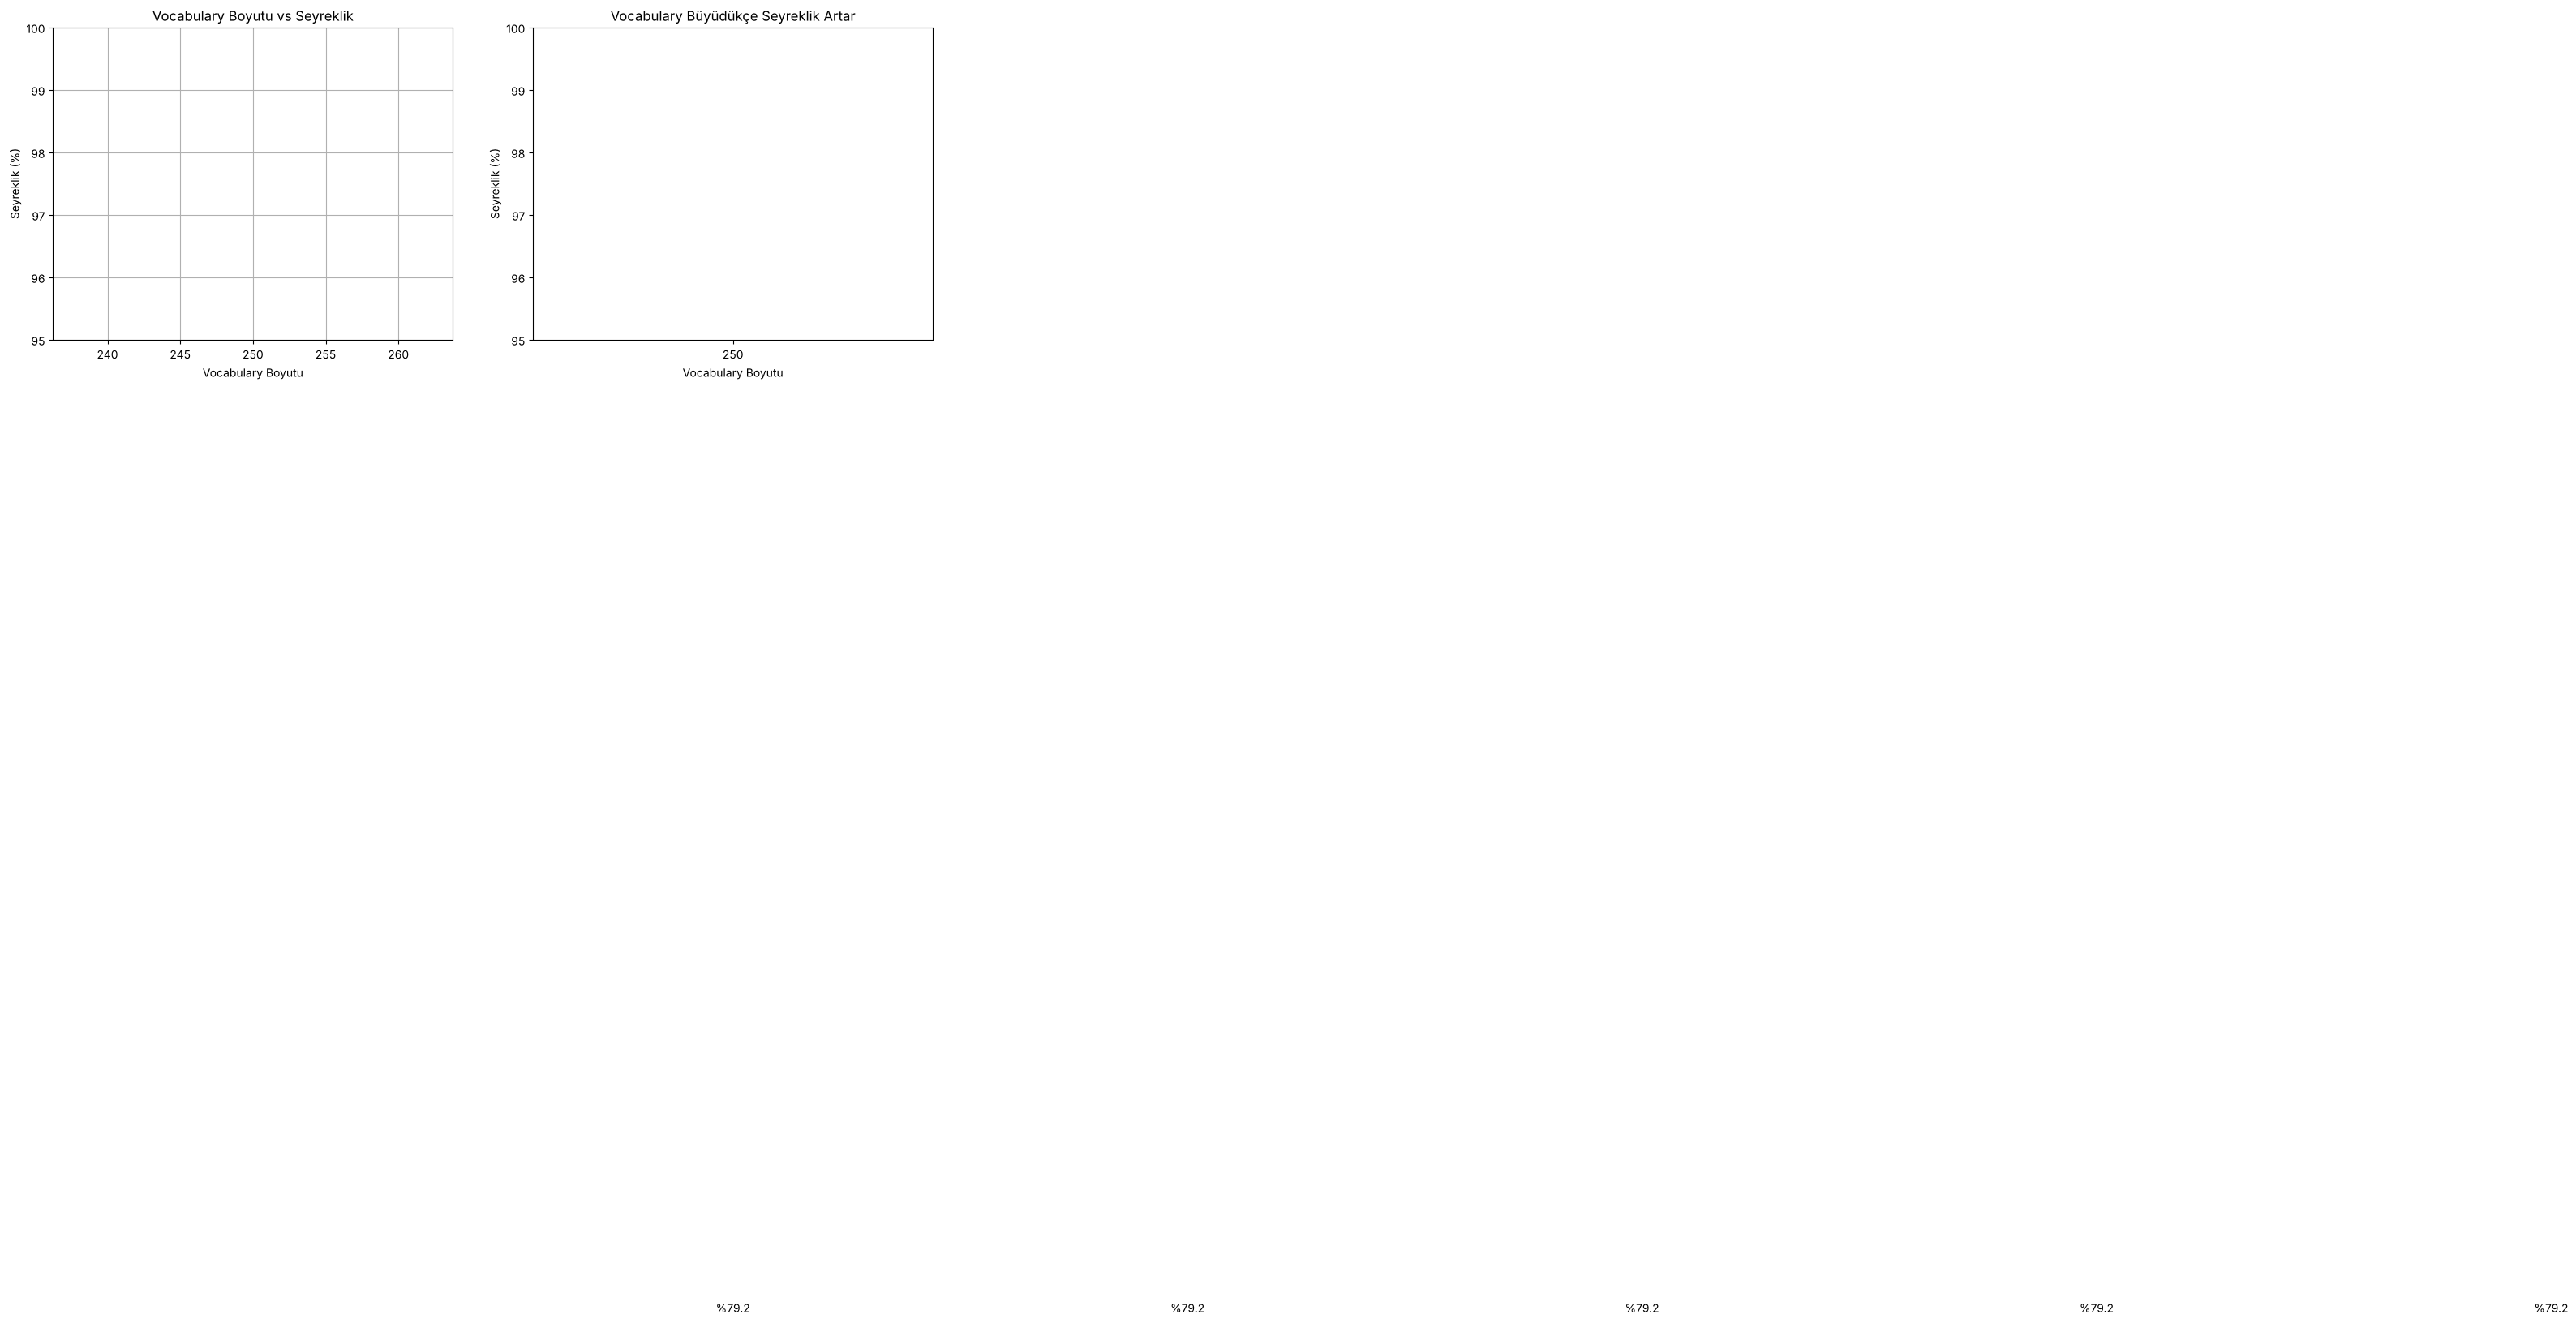

In [12]:
# Seyrekliğin vocabulary büyüklüğü ile ilişkisi
print("Vocabulary Büyüklüğüne Karşı Seyreklik:\n")

max_features_degerleri = [500, 2000, 5000, 10000, 20000]
seyreklikler = []
boyutlar = []

for mf in max_features_degerleri:
    v = TfidfVectorizer(max_features=mf)
    m = v.fit_transform(buyuk_dokumanlar)
    toplam = m.shape[0] * m.shape[1]
    nnz = m.nnz
    sey = 100 * (1 - nnz / toplam)
    seyreklikler.append(sey)
    boyutlar.append(m.shape[1])
    print(f"  max_features={mf:5d} -> gerçek boyut={m.shape[1]:5d}, seyreklik=%{sey:.2f}")

# Görselleştir
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(boyutlar, seyreklikler, marker='o', linewidth=2)
axes[0].set_xlabel("Vocabulary Boyutu")
axes[0].set_ylabel("Seyreklik (%)")
axes[0].set_title("Vocabulary Boyutu vs Seyreklik")
axes[0].grid(True)
axes[0].set_ylim(95, 100)

axes[1].bar([str(b) for b in boyutlar], seyreklikler, color='coral')
axes[1].set_xlabel("Vocabulary Boyutu")
axes[1].set_ylabel("Seyreklik (%)")
axes[1].set_title("Vocabulary Büyüdükçe Seyreklik Artar")
axes[1].set_ylim(95, 100)
for i, v in enumerate(seyreklikler):
    axes[1].text(i, v + 0.2, f"%{v:.1f}", ha='center')

plt.tight_layout()
plt.show()

In [13]:
# Hafıza kullanımı karşılaştırması: Seyrek vs Yoğun matris
print("Hafıza Kullanımı: Seyrek (Sparse) vs Yoğun (Dense) Matris\n")

v6 = TfidfVectorizer(max_features=5000)
m_sparse = v6.fit_transform(buyuk_dokumanlar)

# Hafıza hesaplamaları
# Sparse matris: nnz * (8 byte + 4 byte + 4 byte) ≈ nnz * 16 byte
sparse_memory = m_sparse.nnz * 16 / (1024 * 1024)

# Dense matris: shape[0] * shape[1] * 8 byte
dense_memory = m_sparse.shape[0] * m_sparse.shape[1] * 8 / (1024 * 1024)

print(f"Matris boyutu: {m_sparse.shape[0]} x {m_sparse.shape[1]}")
print(f"  Seyrek matris hafızası: {sparse_memory:.2f} MB")
print(f"  Yoğun matris hafızası  : {dense_memory:.2f} MB")
print(f"  Tasarruf               : {dense_memory / sparse_memory:.1f}x daha az hafıza!")
print()
print(f"Eğer 1 milyon doküman olsaydı (20000 kelime dağarcığı ile):")
print(f"  Seyrek: yaklaşık ~150 MB")
print(f"  Yoğun : 1,000,000 × 20000 × 8 = 8,000 MB = 8 GB")

Hafıza Kullanımı: Seyrek (Sparse) vs Yoğun (Dense) Matris



Matris boyutu: 10000 x 250
  Seyrek matris hafızası: 7.92 MB
  Yoğun matris hafızası  : 19.07 MB
  Tasarruf               : 2.4x daha az hafıza!

Eğer 1 milyon doküman olsaydı (20000 kelime dağarcığı ile):
  Seyrek: yaklaşık ~150 MB
  Yoğun : 1,000,000 × 20000 × 8 = 8,000 MB = 8 GB


---
## 6.3.1 Seyrek TF-IDF Matrisi Üzerinde Lineer Regresyon

Yukarıda 10.000 × 250 boyutlu TF-IDF matrisinin yaklaşık **%79'unun sıfır** olduğunu gördük. Peki bu seyrek ve görece yüksek boyutlu temsil, üzerine kurulan bir **lineer regresyon** modelini nasıl etkiler?

**Deney düzeni:** Dokümanlar rastgele üretildiği için doğal bir hedef değişkenleri yok. Bu yüzden **gizli, bilinen bir kural** ile sentetik bir hedef tanımlıyoruz: *"Ekonomi Gündem Skoru"*.

- Ekonomi/finans kelimeleri (ekonomi, faiz, borsa, …) skoru **artırır** (ağırlık +1 ile +3 arası)
- Sağlık kelimeleri (hasta, ilac, doktor, …) skoru **düşürür** (ağırlık −1 ile −3 arası)
- Diğer ~226 kelimenin ağırlığı **sıfır**dır (gürültü öznitelikleri)

$$y = 100 \cdot \sum_{w} \beta_w \cdot \frac{\text{count}(w, d)}{|d|} + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\, 2^2)$$

Gerçek kuralı bildiğimiz için modellerin **ne kadar iyi tahmin ettiğini** ve **doğru kelimeleri bulup bulamadığını** ölçebiliriz. İncelenecek sorular:

1. Seyrek matris doğrudan lineer regresyona verilebilir mi? Yoğun matrise göre maliyeti nedir?
2. Örnek sayısı (n) öznitelik sayısına (p) yaklaştığında ne olur?
3. N-gram ile boyut ve seyreklik patlayınca ne olur?
4. Lasso (L1) seyrek bir kuralı geri bulabilir mi?
5. SVD ile yoğunlaştırma regresyona yardımcı olur mu?

Gerçek kuralda sıfırdan farklı ağırlık: 24 / 250 kelime
Hedef (y) ortalama: 6.83, std: 9.28, min: -35.56, max: 62.77
Gürültü std: 2.0  →  ulaşılabilir teorik R² tavanı ≈ 0.959


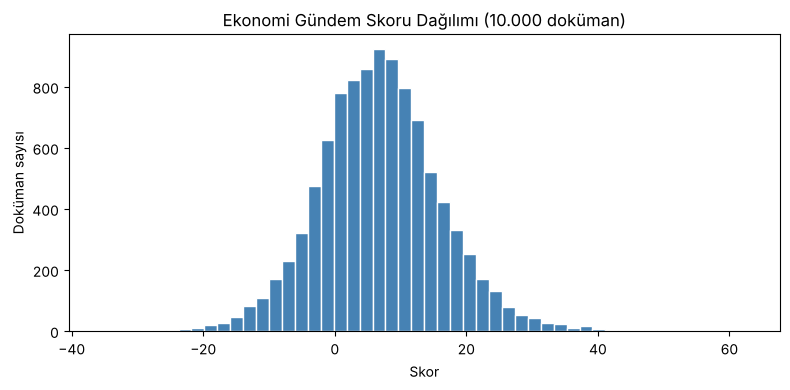

In [14]:
# Sentetik hedef değişken: "Ekonomi Gündem Skoru"
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.metrics import r2_score, mean_squared_error
import time
from sklearn.decomposition import TruncatedSVD

RIDGE_ALFALAR = np.logspace(-4, 2, 25)  # RidgeCV için aday ceza katsayıları

rng = np.random.default_rng(0)

pozitif_kelimeler = ["ekonomi", "enflasyon", "faiz", "piyasa", "yatirim", "borsa", "hisse", "tahvil",
                     "butce", "vergi", "gelir", "kar", "uretim", "finans", "kredi", "doviz"]
negatif_kelimeler = ["saglik", "hastalik", "tedavi", "ilac", "doktor", "hasta", "ameliyat", "teshis"]

gercek_agirlik = {w: rng.uniform(1, 3) for w in pozitif_kelimeler}
gercek_agirlik.update({w: -rng.uniform(1, 3) for w in negatif_kelimeler})

def ekonomi_skoru(doc):
    tokenler = doc.split()
    return 100 * sum(gercek_agirlik.get(t, 0.0) for t in tokenler) / len(tokenler)

y_temiz = np.array([ekonomi_skoru(d) for d in buyuk_dokumanlar])
y = y_temiz + rng.normal(0, 2.0, size=len(y_temiz))

teorik_r2 = np.var(y_temiz) / np.var(y)

print(f"Gerçek kuralda sıfırdan farklı ağırlık: {len(gercek_agirlik)} / {m5.shape[1]} kelime")
print(f"Hedef (y) ortalama: {y.mean():.2f}, std: {y.std():.2f}, min: {y.min():.2f}, max: {y.max():.2f}")
print(f"Gürültü std: 2.0  →  ulaşılabilir teorik R² tavanı ≈ {teorik_r2:.3f}")

plt.figure(figsize=(8, 4))
plt.hist(y, bins=50, color="steelblue", edgecolor="white")
plt.title("Ekonomi Gündem Skoru Dağılımı (10.000 doküman)")
plt.xlabel("Skor")
plt.ylabel("Doküman sayısı")
plt.tight_layout()
plt.show()

### Deney 1: Seyrek matrisle doğrudan lineer regresyon

Scikit-learn'ün `LinearRegression` sınıfı `scipy.sparse` matrisleri doğrudan kabul eder (arka planda `lsqr` çözücüsünü kullanır). Matrisi `.toarray()` ile yoğunlaştırmaya gerek yoktur. Önce temel performansı ölçelim, sonra aynı modeli yoğun matrisle eğitip süre ve hafızayı karşılaştıralım.

In [15]:
# m5: yukarıda 10.000 doküman üzerinde oluşturulan TF-IDF matrisi (10000 x 250, seyrek)
X = m5
idx = np.arange(X.shape[0])
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

def degerlendir(model, Xtr, ytr, Xte, yte):
    t0 = time.perf_counter()
    model.fit(Xtr, ytr)
    sure = time.perf_counter() - t0
    return {
        "train R²": r2_score(ytr, model.predict(Xtr)),
        "test R²": r2_score(yte, model.predict(Xte)),
        "test RMSE": np.sqrt(mean_squared_error(yte, model.predict(Xte))),
        "eğitim süresi (ms)": 1000 * sure,
    }

sonuc_seyrek = degerlendir(LinearRegression(), X_train, y_train, X_test, y_test)

X_train_yogun, X_test_yogun = X_train.toarray(), X_test.toarray()
sonuc_yogun = degerlendir(LinearRegression(), X_train_yogun, y_train, X_test_yogun, y_test)

df_d1 = pd.DataFrame([sonuc_seyrek, sonuc_yogun], index=["Seyrek (CSR) girdi", "Yoğun (dense) girdi"])
df_d1["girdi hafızası (MB)"] = [
    (X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes) / 1024**2,
    X_train_yogun.nbytes / 1024**2,
]
display(df_d1.round(4))

print(f"\nTeorik R² tavanı ≈ {teorik_r2:.3f}")
print("İki girdi aynı modeli öğrenir; fark yalnızca hafıza ve hesaplama yolundadır.")
print("Test R²'nin tavanın altında kalmasının bir nedeni: hedef kelime ORANLARINDAN üretildi,")
print("TF-IDF ise IDF ile ölçeklenip L2-normalize edilmiş değerler içerir (doğrusal olmayan bir dönüşüm).")

,train R²,test R²,test RMSE,eğitim süresi (ms),girdi hafızası (MB)
Seyrek (CSR) girdi,0.9197,0.9101,2.7286,13.7560,4.7786
Yoğun (dense) girdi,0.9197,0.9101,2.7286,103.6678,15.2588



Teorik R² tavanı ≈ 0.959
İki girdi aynı modeli öğrenir; fark yalnızca hafıza ve hesaplama yolundadır.
Test R²'nin tavanın altında kalmasının bir nedeni: hedef kelime ORANLARINDAN üretildi,
TF-IDF ise IDF ile ölçeklenip L2-normalize edilmiş değerler içerir (doğrusal olmayan bir dönüşüm).


### Deney 2: Örnek sayısı öznitelik sayısına yaklaşınca (n ≈ p)

250 özniteliğimiz var. Eğitim kümesini 100'den 8.000'e kadar büyütüp **sabit bir test kümesi** üzerinde üç modeli karşılaştırıyoruz:

- **LinearRegression** (düzenlileştirme yok, OLS)
- **RidgeCV** (L2 cezası; α eğitim verisinde çapraz doğrulama ile seçilir)
- **Lasso** (L1 cezası, α = 0.01 sabit; katsayıları tam sıfıra itebilir)

Beklenti: `n ≤ p` bölgesinde OLS veriyi ezberler (train R² ≈ 1), testte çöker. Özellikle **n ≈ p** civarında test hatası tepe yapar (*interpolasyon eşiği*).

In [16]:
n_degerleri = [100, 150, 200, 240, 250, 260, 300, 400, 600, 1000, 2000, 4000, 8000]
modeller = {
    "LinearRegression": lambda: LinearRegression(),
    "RidgeCV": lambda: RidgeCV(alphas=RIDGE_ALFALAR),
    "Lasso (α=0.01)": lambda: Lasso(alpha=0.01, max_iter=20000),
}

rng_ornek = np.random.default_rng(1)
satirlar = []
for n in n_degerleri:
    secim = rng_ornek.choice(len(idx_train), size=n, replace=False)
    Xn, yn = X_train[secim], y_train[secim]
    for ad, yap in modeller.items():
        r = degerlendir(yap(), Xn, yn, X_test, y_test)
        satirlar.append({"n_train": n, "model": ad, **r})

df_ogrenme = pd.DataFrame(satirlar)
tablo = df_ogrenme.pivot(index="n_train", columns="model", values="test R²")
print(f"Öznitelik sayısı p = {X.shape[1]}\n")
print("Test R² (sabit 2.000 dokümanlık test kümesi):")
display(tablo.round(3))

Öznitelik sayısı p = 250

Test R² (sabit 2.000 dokümanlık test kümesi):


model,Lasso (α=0.01),LinearRegression,RidgeCV
n_train,,,
100,0.677,0.361,0.361
150,0.806,0.403,0.430
200,0.811,0.210,0.537
240,0.832,-0.455,0.623
250,0.866,-8.752,0.699
260,0.866,-1.667,0.617
300,0.863,0.374,0.700
400,0.878,0.788,0.794
600,0.879,0.843,0.848


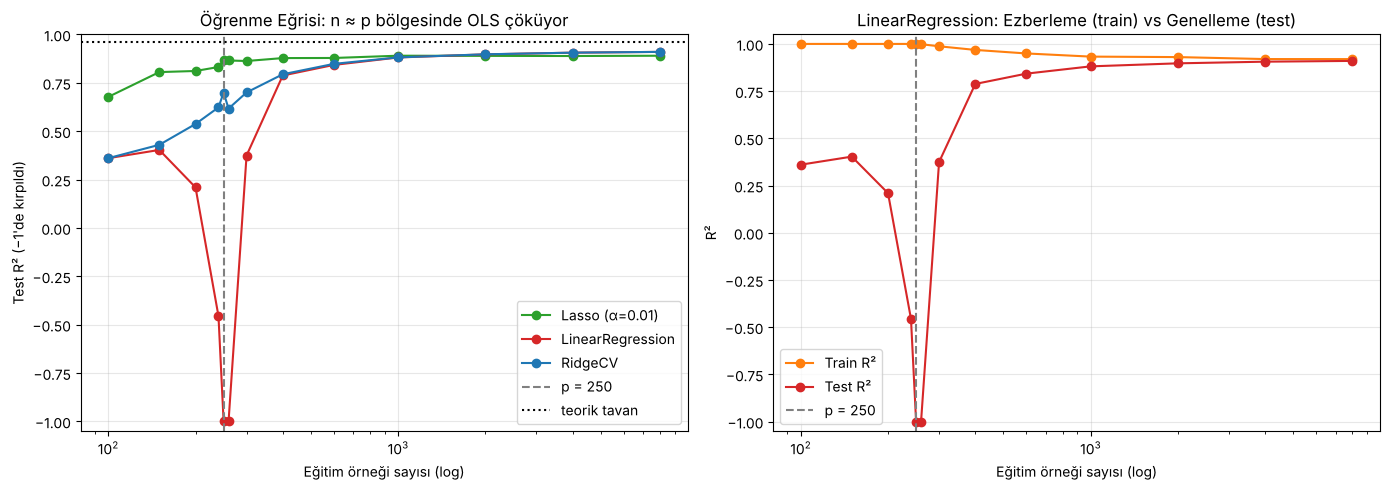

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
renk = {"LinearRegression": "tab:red", "RidgeCV": "tab:blue", "Lasso (α=0.01)": "tab:green"}

for ad, grup in df_ogrenme.groupby("model"):
    axes[0].plot(grup["n_train"], grup["test R²"].clip(lower=-1), marker="o", label=ad, color=renk[ad])
axes[0].axvline(X.shape[1], color="gray", linestyle="--", label=f"p = {X.shape[1]}")
axes[0].axhline(teorik_r2, color="black", linestyle=":", label="teorik tavan")
axes[0].set_xscale("log")
axes[0].set_ylim(-1.05, 1.0)
axes[0].set_xlabel("Eğitim örneği sayısı (log)")
axes[0].set_ylabel("Test R² (−1'de kırpıldı)")
axes[0].set_title("Öğrenme Eğrisi: n ≈ p bölgesinde OLS çöküyor")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

ols = df_ogrenme[df_ogrenme["model"] == "LinearRegression"]
axes[1].plot(ols["n_train"], ols["train R²"], marker="o", label="Train R²", color="tab:orange")
axes[1].plot(ols["n_train"], ols["test R²"].clip(lower=-1), marker="o", label="Test R²", color="tab:red")
axes[1].axvline(X.shape[1], color="gray", linestyle="--", label=f"p = {X.shape[1]}")
axes[1].set_xscale("log")
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_xlabel("Eğitim örneği sayısı (log)")
axes[1].set_ylabel("R²")
axes[1].set_title("LinearRegression: Ezberleme (train) vs Genelleme (test)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Deney 3: N-gram ile boyut ve seyreklik patlaması

Bağlam sorununu (6.2) çözmek için bigram eklemek cazip görünür. Ancak 250 kelimelik sözlükte bigramlar on binlerce yeni öznitelik doğurur ve bunların neredeyse hepsi hedefle **ilgisizdir**. Aynı 2.000 eğitim dokümanıyla unigram ve unigram+bigram temsillerini karşılaştıralım.

> Not: Vektörleştirici etiket kullanmadığı için tüm dokümanlar üzerinde `fit` edildi; bu bir veri sızıntısı oluşturmaz.

In [18]:
v_bigram = TfidfVectorizer(ngram_range=(1, 2))
X_bigram = v_bigram.fit_transform(buyuk_dokumanlar)

n_kucuk = 2000
secim = np.random.default_rng(2).choice(len(idx_train), size=n_kucuk, replace=False)
tr = idx_train[secim]

temsiller = {"Unigram": X, "Unigram + Bigram": X_bigram}
satirlar = []
for t_ad, Xt in temsiller.items():
    seyreklik_t = 100 * (1 - Xt.nnz / (Xt.shape[0] * Xt.shape[1]))
    for m_ad, yap in [("LinearRegression", lambda: LinearRegression()),
                      ("RidgeCV", lambda: RidgeCV(alphas=RIDGE_ALFALAR)),
                      ("Lasso (α=0.01)", lambda: Lasso(alpha=0.01, max_iter=50000))]:
        r = degerlendir(yap(), Xt[tr], y[tr], Xt[idx_test], y_test)
        satirlar.append({"temsil": t_ad, "öznitelik (p)": Xt.shape[1],
                         "seyreklik %": seyreklik_t, "model": m_ad, **r})

df_ngram_reg = pd.DataFrame(satirlar).set_index(["temsil", "model"])
print(f"Eğitim örneği n = {n_kucuk}\n")
display(df_ngram_reg.round(3))

print(f"\nBigram ile p = {X_bigram.shape[1]:,} > n = {n_kucuk:,}  →  OLS'nin tek bir çözümü yoktur;")
print("lsqr en küçük normlu çözümü döndürür ve eğitim verisini ezberler.")

lasso_bigram = Lasso(alpha=0.01, max_iter=50000).fit(X_bigram[tr], y[tr])
secilen_ozn = v_bigram.get_feature_names_out()[lasso_bigram.coef_ != 0]
print(f"\nLasso {X_bigram.shape[1]:,} öznitelikten yalnızca {len(secilen_ozn)} tanesini tuttu:")
print(f"  bigram sayısı: {sum(' ' in o for o in secilen_ozn)}  |  kuraldaki kelime: {sum(o in gercek_agirlik for o in secilen_ozn)}")
print("Ridge tüm katsayıları birlikte küçültür; ilgisiz binlerce özniteliği ayıklayamaz.")

Eğitim örneği n = 2000



öznitelik (p)  seyreklik %  train R²  \
temsil           model                                                    
Unigram          LinearRegression            250       79.232     0.928   
                 RidgeCV                     250       79.232     0.928   
                 Lasso (α=0.01)              250       79.232     0.897   
Unigram + Bigram LinearRegression          62745       99.825     1.000   
                 RidgeCV                   62745       99.825     1.000   
                 Lasso (α=0.01)            62745       99.825     0.818   

                                   test R²  test RMSE  eğitim süresi (ms)  
temsil           model                                                     
Unigram          LinearRegression    0.901      2.857               6.587  
                 RidgeCV             0.902      2.852             411.059  
                 Lasso (α=0.01)      0.893      2.974               5.564  
Unigram + Bigram LinearRegression    0.641      5.448              36.476  
                 RidgeCV             0.641      5.448            2087.884  
                 Lasso (α=0.01)      0.824      3.822             175.564


Bigram ile p = 62,745 > n = 2,000  →  OLS'nin tek bir çözümü yoktur;
lsqr en küçük normlu çözümü döndürür ve eğitim verisini ezberler.



Lasso 62,745 öznitelikten yalnızca 24 tanesini tuttu:
  bigram sayısı: 0  |  kuraldaki kelime: 24
Ridge tüm katsayıları birlikte küçültür; ilgisiz binlerce özniteliği ayıklayamaz.


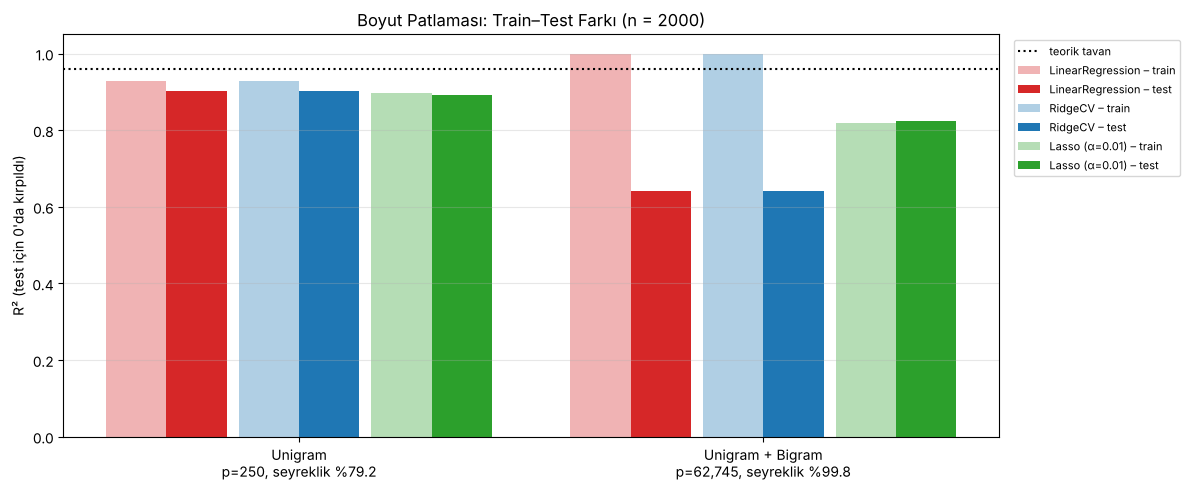

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
d = df_ngram_reg.reset_index()
x = np.arange(2)
genislik = 0.13
model_renk = [("LinearRegression", "tab:red"), ("RidgeCV", "tab:blue"), ("Lasso (α=0.01)", "tab:green")]
for i, (m_ad, renk_m) in enumerate(model_renk):
    alt = d[d["model"] == m_ad]
    merkez = x + (i - 1) * 2.2 * genislik
    ax.bar(merkez - genislik / 2, alt["train R²"], genislik, color=renk_m, alpha=0.35,
           label=f"{m_ad} – train")
    ax.bar(merkez + genislik / 2, alt["test R²"].clip(lower=0), genislik, color=renk_m,
           label=f"{m_ad} – test")
ax.set_xticks(x)
ax.set_xticklabels([f"{t}\np={p:,}, seyreklik %{s:.1f}" for t, p, s in
                    d.drop_duplicates("temsil")[["temsil", "öznitelik (p)", "seyreklik %"]].values])
ax.axhline(teorik_r2, color="black", linestyle=":", label="teorik tavan")
ax.set_ylabel("R² (test için 0'da kırpıldı)")
ax.set_title(f"Boyut Patlaması: Train–Test Farkı (n = {n_kucuk})")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Deney 4: Lasso seyrek kuralı geri bulabilir mi?

Gerçek kuralda 250 kelimeden yalnızca 24'ünün ağırlığı sıfırdan farklı. L1 cezası katsayıları tam sıfıra itebildiği için, **seyrek veride seyrek bir model** arayan doğal bir araçtır. Ceza katsayısını (α) 5 katlı çapraz doğrulama ile seçiyoruz.

In [20]:
lasso_cv = LassoCV(cv=5, alphas=40, max_iter=20000, random_state=0)
lasso_cv.fit(X_train, y_train)
ridge = RidgeCV(alphas=RIDGE_ALFALAR).fit(X_train, y_train)

kelimeler = v5.get_feature_names_out()
df_kats = pd.DataFrame({
    "kelime": kelimeler,
    "gerçek β": [gercek_agirlik.get(k, 0.0) for k in kelimeler],
    "Lasso": lasso_cv.coef_,
    "Ridge": ridge.coef_,
})
df_kats["kuralda mı"] = df_kats["gerçek β"] != 0

secilen = df_kats["Lasso"] != 0
dogru_secilen = (secilen & df_kats["kuralda mı"]).sum()
yanlis_secilen = (secilen & ~df_kats["kuralda mı"]).sum()
isaret_dogru = (np.sign(df_kats.loc[df_kats["kuralda mı"], "Lasso"]) ==
                np.sign(df_kats.loc[df_kats["kuralda mı"], "gerçek β"])).mean()

print(f"LassoCV'nin seçtiği α = {lasso_cv.alpha_:.5f}   |   RidgeCV'nin seçtiği α = {ridge.alpha_:.5f}")
print(f"Lasso test R² = {r2_score(y_test, lasso_cv.predict(X_test)):.3f}   |   Ridge test R² = {r2_score(y_test, ridge.predict(X_test)):.3f}")
print(f"\nLasso'nun sıfırdan farklı bıraktığı katsayı: {secilen.sum()} / {len(kelimeler)}")
print(f"  Kuraldaki 24 kelimeden yakalanan : {dogru_secilen}")
print(f"  Kuralda olmayan ama seçilen      : {yanlis_secilen}")
print(f"  Yakalanan kelimelerde işaret doğruluğu: %{100 * isaret_dogru:.0f}")
print(f"Ridge'in tam sıfır katsayısı: {(df_kats['Ridge'] == 0).sum()} (L2 sıfıra itmez, yalnızca küçültür)")

print("\nLasso'nun en büyük 10 katsayısı:")
display(df_kats.reindex(df_kats["Lasso"].abs().sort_values(ascending=False).index)
        .head(10)[["kelime", "gerçek β", "Lasso", "Ridge"]].round(3).reset_index(drop=True))

LassoCV'nin seçtiği α = 0.00029   |   RidgeCV'nin seçtiği α = 0.05623
Lasso test R² = 0.910   |   Ridge test R² = 0.910

Lasso'nun sıfırdan farklı bıraktığı katsayı: 244 / 250
  Kuraldaki 24 kelimeden yakalanan : 24
  Kuralda olmayan ama seçilen      : 220
  Yakalanan kelimelerde işaret doğruluğu: %100
Ridge'in tam sıfır katsayısı: 0 (L2 sıfıra itmez, yalnızca küçültür)

Lasso'nun en büyük 10 katsayısı:


,kelime,gerçek β,Lasso,Ridge
0,vergi,2.870,43.323,43.368
1,saglik,-2.726,-43.129,-43.083
2,borsa,2.826,41.154,41.185
3,uretim,2.715,40.775,40.795
4,yatirim,2.627,40.184,40.219
5,ameliyat,-2.341,-38.275,-38.271
6,gelir,2.632,38.136,38.182
7,tahvil,2.459,37.547,37.599
8,kredi,2.459,36.892,36.930
9,teshis,-2.294,-35.291,-35.294


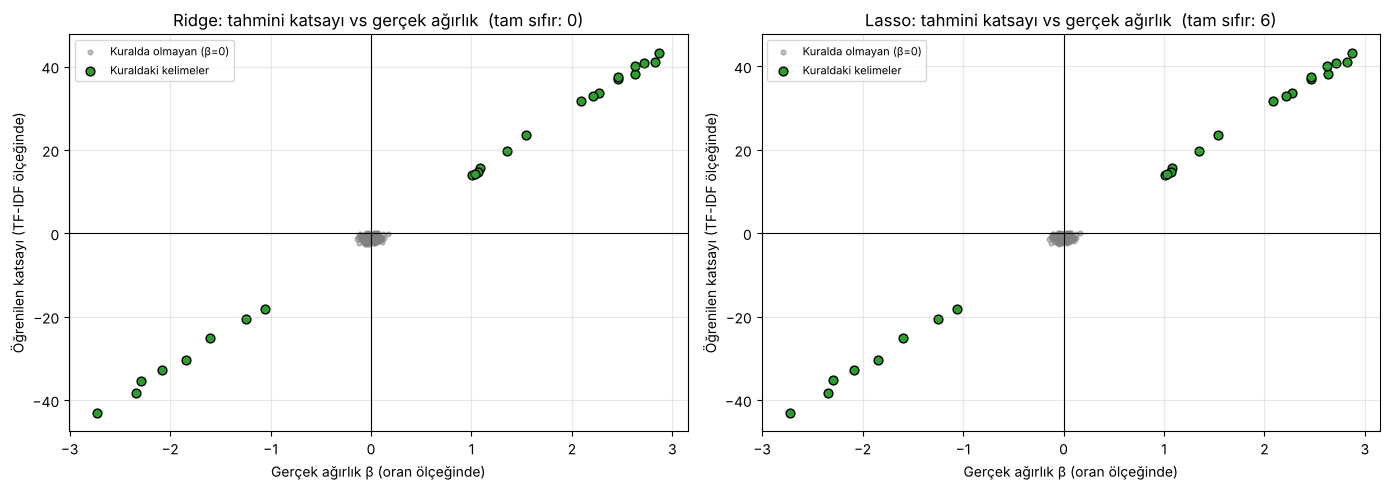

Katsayılar farklı ölçeklerde (oran vs TF-IDF) olduğu için birebir eşleşme beklenmez;
önemli olan işaret, sıralama ve gürültü kelimelerinin sıfıra itilmesidir.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, model_ad in zip(axes, ["Ridge", "Lasso"]):
    gurultu = df_kats[~df_kats["kuralda mı"]]
    kural = df_kats[df_kats["kuralda mı"]]
    ax.scatter(gurultu["gerçek β"] + np.random.default_rng(3).normal(0, 0.05, len(gurultu)),
               gurultu[model_ad], s=12, color="gray", alpha=0.5, label="Kuralda olmayan (β=0)")
    ax.scatter(kural["gerçek β"], kural[model_ad], s=40, color="tab:green", edgecolors="black",
               label="Kuraldaki kelimeler")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    sifir = (df_kats[model_ad] == 0).sum()
    ax.set_title(f"{model_ad}: tahmini katsayı vs gerçek ağırlık  (tam sıfır: {sifir})")
    ax.set_xlabel("Gerçek ağırlık β (oran ölçeğinde)")
    ax.set_ylabel("Öğrenilen katsayı (TF-IDF ölçeğinde)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Katsayılar farklı ölçeklerde (oran vs TF-IDF) olduğu için birebir eşleşme beklenmez;")
print("önemli olan işaret, sıralama ve gürültü kelimelerinin sıfıra itilmesidir.")

#### Tahmin için en iyi α ≠ yorum için en iyi α

Çapraz doğrulama **tahmin hatasını** en aza indiren α'yı seçer; bu genellikle çok küçük bir cezadır ve gürültü kelimelerinin çoğu küçük ama sıfır olmayan katsayılarla modelde kalır. Amaç **hangi kelimelerin gerçekten önemli olduğunu** bulmaksa, cezayı biraz artırmak gerekir. Aşağıda α'yı tarayıp seçilen kelimeleri gerçek kuralla karşılaştırıyoruz.

,α,seçilen kelime,doğru seçilen (24'ten),yanlış seçilen,test R²
0,0.000,244,24,220,0.910
1,0.001,237,24,213,0.910
2,0.003,208,24,184,0.907
3,0.005,142,24,118,0.902
4,0.010,29,24,5,0.890
5,0.015,24,24,0,0.879
6,0.020,24,24,0,0.865
7,0.030,24,24,0,0.823
8,0.040,24,24,0,0.764
9,0.050,20,20,0,0.695


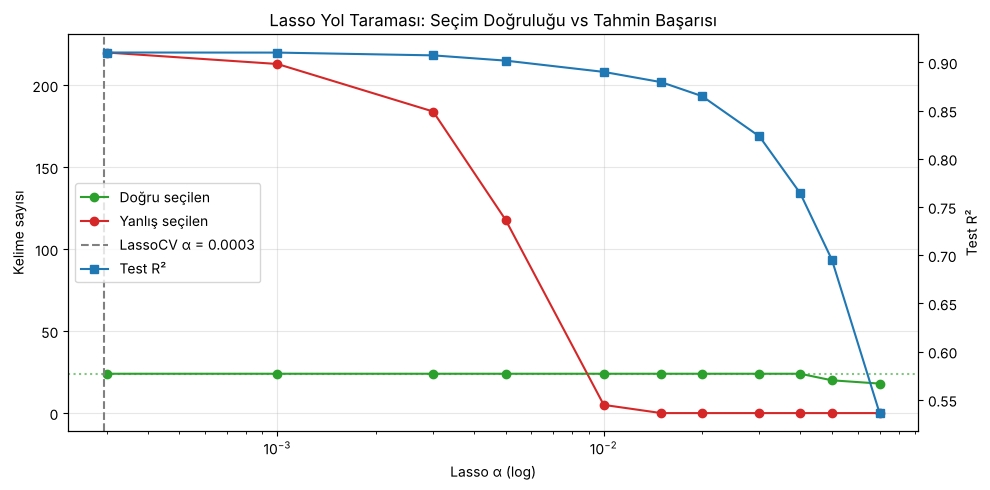

α ∈ [0.015, 0.04] aralığında Lasso gerçek kuralı BİREBİR buluyor (24 doğru, 0 yanlış); bedeli test R²'de 0.031 puanlık kayıp.


In [22]:
alfa_degerleri = [0.0003, 0.001, 0.003, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.07]
satirlar = []
for a in alfa_degerleri:
    l = Lasso(alpha=a, max_iter=50000).fit(X_train, y_train)
    nz = l.coef_ != 0
    satirlar.append({
        "α": a,
        "seçilen kelime": nz.sum(),
        "doğru seçilen (24'ten)": (nz & df_kats["kuralda mı"].values).sum(),
        "yanlış seçilen": (nz & ~df_kats["kuralda mı"].values).sum(),
        "test R²": r2_score(y_test, l.predict(X_test)),
    })
df_alfa = pd.DataFrame(satirlar)
display(df_alfa.round(3))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_alfa["α"], df_alfa["doğru seçilen (24'ten)"], marker="o", color="tab:green", label="Doğru seçilen")
ax1.plot(df_alfa["α"], df_alfa["yanlış seçilen"], marker="o", color="tab:red", label="Yanlış seçilen")
ax1.axhline(24, color="tab:green", linestyle=":", alpha=0.6)
ax1.set_xscale("log")
ax1.set_xlabel("Lasso α (log)")
ax1.set_ylabel("Kelime sayısı")
ax2 = ax1.twinx()
ax2.plot(df_alfa["α"], df_alfa["test R²"], marker="s", color="tab:blue", label="Test R²")
ax2.set_ylabel("Test R²")
ax1.axvline(lasso_cv.alpha_, color="gray", linestyle="--", label=f"LassoCV α = {lasso_cv.alpha_:.4f}")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center left")
ax1.set_title("Lasso Yol Taraması: Seçim Doğruluğu vs Tahmin Başarısı")
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

tam = df_alfa[(df_alfa["doğru seçilen (24'ten)"] == 24) & (df_alfa["yanlış seçilen"] == 0)]
if len(tam):
    print(f"α ∈ [{tam['α'].min()}, {tam['α'].max()}] aralığında Lasso gerçek kuralı BİREBİR buluyor "
          f"(24 doğru, 0 yanlış); bedeli test R²'de {df_alfa['test R²'].max() - tam['test R²'].max():.3f} puanlık kayıp.")

### Deney 5: SVD ile yoğunlaştırma regresyona yardımcı olur mu?

Bölüm 6.4 ve 8'de önerilen çözümlerden biri, seyrek TF-IDF matrisini **TruncatedSVD** ile düşük boyutlu yoğun bir matrise indirgemektir. SVD gözetimsizdir: hedefi bilmeden **en çok varyansı taşıyan** yönleri seçer. Bu yönler bizim hedefimizle örtüşmeyebilir.

,temsil,boyut,açıklanan varyans %,test R²,test RMSE
0,SVD (yoğun),5,2.751,0.018,9.016
1,SVD (yoğun),10,5.273,0.007,9.068
2,SVD (yoğun),25,12.622,0.093,8.663
3,SVD (yoğun),50,24.299,0.111,8.581
4,SVD (yoğun),100,46.177,0.374,7.201
5,SVD (yoğun),150,66.080,0.550,6.102
6,SVD (yoğun),200,84.120,0.690,5.067
7,Seyrek TF-IDF (tam),250,100.000,0.910,2.728


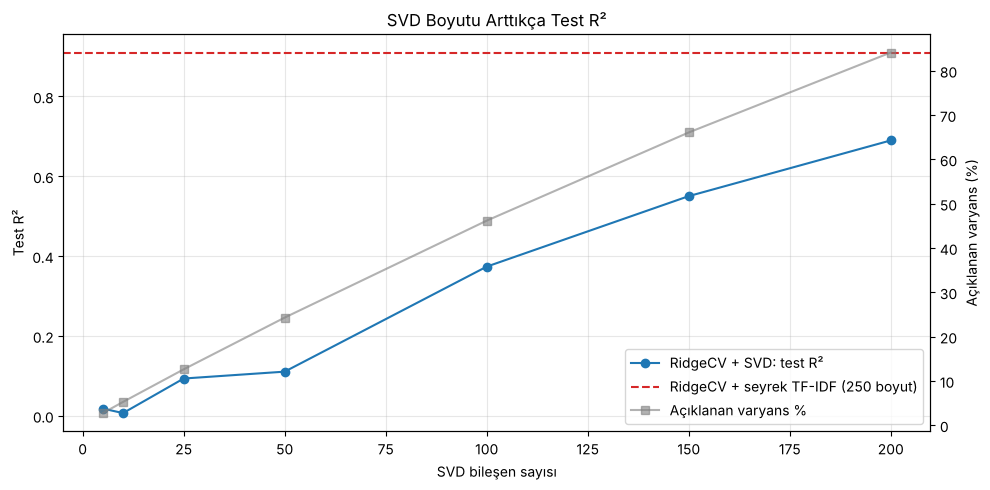

In [23]:
bilesen_sayilari = [5, 10, 25, 50, 100, 150, 200]
satirlar = []
for k in bilesen_sayilari:
    svd_k = TruncatedSVD(n_components=k, random_state=42)
    Z_train = svd_k.fit_transform(X_train)
    Z_test = svd_k.transform(X_test)
    r = degerlendir(RidgeCV(alphas=RIDGE_ALFALAR), Z_train, y_train, Z_test, y_test)
    satirlar.append({"boyut": k, "açıklanan varyans %": 100 * svd_k.explained_variance_ratio_.sum(), **r})

r_tam = degerlendir(RidgeCV(alphas=RIDGE_ALFALAR), X_train, y_train, X_test, y_test)
satirlar.append({"boyut": X.shape[1], "açıklanan varyans %": 100.0, **r_tam})
df_svd = pd.DataFrame(satirlar)
df_svd["temsil"] = ["SVD (yoğun)"] * len(bilesen_sayilari) + ["Seyrek TF-IDF (tam)"]
display(df_svd[["temsil", "boyut", "açıklanan varyans %", "test R²", "test RMSE"]].round(3))

fig, ax1 = plt.subplots(figsize=(10, 5))
svd_kismi = df_svd.iloc[:-1]
ax1.plot(svd_kismi["boyut"], svd_kismi["test R²"], marker="o", color="tab:blue", label="RidgeCV + SVD: test R²")
ax1.axhline(r_tam["test R²"], color="tab:red", linestyle="--", label="RidgeCV + seyrek TF-IDF (250 boyut)")
ax1.set_xlabel("SVD bileşen sayısı")
ax1.set_ylabel("Test R²")
ax2 = ax1.twinx()
ax2.plot(svd_kismi["boyut"], svd_kismi["açıklanan varyans %"], marker="s", color="gray", alpha=0.6,
         label="Açıklanan varyans %")
ax2.set_ylabel("Açıklanan varyans (%)")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right")
ax1.set_title("SVD Boyutu Arttıkça Test R²")
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3.1 Özeti: Seyreklik ve Lineer Regresyon

| Deney | Bulgu | Ders |
|---|---|---|
| **1. Seyrek vs yoğun girdi** | Aynı model (test R² ≈ 0.91); seyrek girdi ~3 kat az hafıza ve ~10 kat hızlı eğitim | Seyrek TF-IDF matrisini `.toarray()` ile yoğunlaştırmayın; scikit-learn doğrudan kabul eder |
| **2. n ≈ p** | OLS, n = 250 = p noktasında test R²'si −8.75'e çöküyor; train R² ise 1.0 (ezber) | Az veride düzenlileştirme şart. n = 100'de Lasso 0.68, OLS 0.36 |
| **3. Bigram patlaması** | p: 250 → 62.745, seyreklik %79 → %99.8. OLS ve Ridge test R² 0.90 → 0.64; Lasso 0.82'de kalıyor | Daha fazla öznitelik ≠ daha fazla bilgi. Ridge ilgisiz öznitelikleri ayıklayamaz, Lasso ayıklar |
| **4. Lasso seçimi** | CV ile seçilen α tahmin için en iyisi ama 220 gürültü kelimesini tutuyor; α ∈ [0.015, 0.04] kuralı birebir buluyor | Tahmin ve yorumlama farklı α ister |
| **5. SVD yoğunlaştırma** | 200 bileşen (%84 varyans) bile test R² 0.69'da kalıyor; tam seyrek temsil 0.91 | Gözetimsiz boyut indirgeme, sinyal birkaç belirli kelimedeyse onu atabilir |

**Genel çıkarım:** Seyreklik tek başına lineer regresyon için bir sorun değildir; asıl risk, seyrekliğe eşlik eden **yüksek boyut / az örnek** dengesizliğidir. Hedef gerçekten birkaç kelimeye bağlıysa, **seyrek veri + seyrek model (Lasso)** ikilisi hem doğru tahmin hem de yorumlanabilir sonuç verir.

---
## 6.4 Boyut Laneti (Curse of Dimensionality)

Yüksek boyutlu (high-dimensional) seyrek vektörler, makine öğrenmesi modelleri için ciddi sorunlar yaratır:

| Sorun | Açıklama |
|---|---|
| **Mesafe anlamsızlaşır** | Yüksek boyutta tüm noktalar birbirine eşit uzaklıkta görünür |
| **Aşırı öğrenme (overfitting)** | Model gürültüyü öğrenir, genelleme yapamaz |
| **Hesaplama maliyeti** | 50.000 boyutlu vektörlerle işlem yapmak yavaştır |
| **Veri seyrekliği** | Anlamlı örüntü bulmak için çok daha fazla veri gerekir |

**Çözüm:** Dimensionality reduction (PCA, SVD) veya embedding yöntemleri (Word2Vec, BERT) ile boyut 50.000'den 100-300'e düşürülür.

Boyut Laneti Gösterimi: Yüksek Boyutta Mesafe Dağılımı



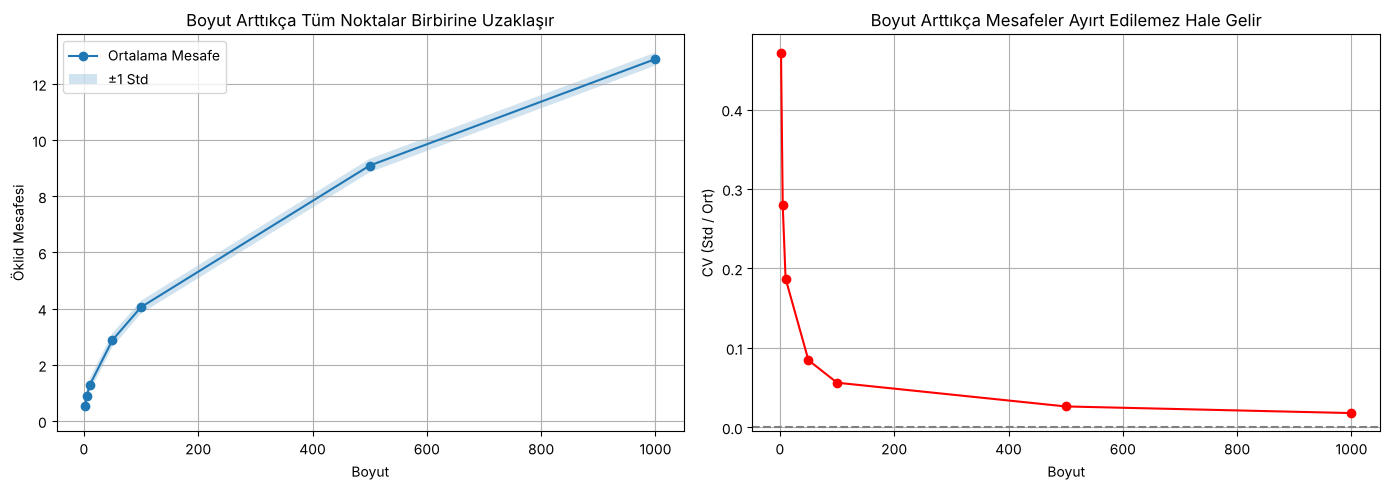

Yorum: Boyut arttıkça tüm noktalar birbirine benzer uzaklıkta olur.
CV değeri 0'a yaklaşır → mesafeler anlamsızlaşır.
TF-IDF'in 50.000 boyutlu vektörlerinde bu etki çok daha şiddetlidir.


In [24]:
# Boyut laneti: Yüksek boyutta mesafelerin anlamını yitirmesi
print("Boyut Laneti Gösterimi: Yüksek Boyutta Mesafe Dağılımı\n")

from scipy.spatial.distance import pdist

np.random.seed(42)

boyutlar = [2, 5, 10, 50, 100, 500, 1000]
noktalar = 50

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mesafe_ort = []
mesafe_std = []

for dim in boyutlar:
    # Birim hiperküpte rastgele noktalar
    data = np.random.uniform(0, 1, (noktalar, dim))
    mesafeler = pdist(data, 'euclidean')
    mesafe_ort.append(np.mean(mesafeler))
    mesafe_std.append(np.std(mesafeler))

axes[0].plot(boyutlar, mesafe_ort, marker='o', label='Ortalama Mesafe')
axes[0].fill_between(boyutlar,
                     np.array(mesafe_ort) - np.array(mesafe_std),
                     np.array(mesafe_ort) + np.array(mesafe_std),
                     alpha=0.2, label='±1 Std')
axes[0].set_xlabel("Boyut")
axes[0].set_ylabel("Öklid Mesafesi")
axes[0].set_title("Boyut Arttıkça Tüm Noktalar Birbirine Uzaklaşır")
axes[0].legend()
axes[0].grid(True)

# CV (değişim katsayısı) = std / mean → düşükse mesafeler ayırt edilemez
cv = [s / m for m, s in zip(mesafe_ort, mesafe_std)]
axes[1].plot(boyutlar, cv, marker='o', color='red')
axes[1].axhline(y=0, color='gray', linestyle='--')
axes[1].set_xlabel("Boyut")
axes[1].set_ylabel("CV (Std / Ort)")
axes[1].set_title("Boyut Arttıkça Mesafeler Ayırt Edilemez Hale Gelir")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Yorum: Boyut arttıkça tüm noktalar birbirine benzer uzaklıkta olur.")
print("CV değeri 0'a yaklaşır → mesafeler anlamsızlaşır.")
print("TF-IDF'in 50.000 boyutlu vektörlerinde bu etki çok daha şiddetlidir.")

---

# 7. Tüm Limitlerin Özeti ve Çözüm Yolları

| Sınırlama | Sorun | Çözüm |
|---|---|---|
| **Anlamsal İlişki** | Eş anlamlı/ilişkili kelimeler farklı ID'ler | Word2Vec, GloVe, FastText |
| **Bağlam Kaybı** | Kelime sırası yok sayılır | N-gram, RNN, LSTM, Transformer |
| **Seyreklik** | Vektörlerin %99+ sıfır | Embedding (yoğun vektörler), SVD |
| **Boyut Laneti** | Yüksek boyutta mesafe/metalar anlamsız | PCA, t-SNE, UMAP |
| **Sabit Kelime Dağarcığı** | Yeni kelimeler eklenemez (OOV sorunu) | FastText (subword), BPE tokenization |

### Ne Zaman TF-IDF Kullanılır?
- Hızlı ve basit bir çözüm gerektiğinde
- Kelime sırasının kritik olmadığı görevlerde (spam tespiti, konu sınıflandırma)
- Küçük-orta ölçekli veri setlerinde
- İlk prototip / baseline model olarak

### Ne Zaman Daha Gelişmiş Yöntemler Gerekir?
- Anlamsal benzerlik önemliyse (arama, soru-cevap)
- Kelime sırası kritikse (sentiment analizi, NER, çeviri)
- Çok büyük ölçekli verilerde
- Çok dilli veya OOV kelimelerin bol olduğu durumlarda

---

# 8. Final: Yoğun Vektör (Dense Embedding) ile Karşılaştırma

TF-IDF'in limitlerini somutlaştırmak için basit bir Word2Vec benzeri yaklaşımla karşılaştırma yapalım.

In [25]:
# TF-IDF vs Basit Embedding: Benzerlik Karşılaştırması

from sklearn.decomposition import TruncatedSVD

test_docs = [
    "kral sarayda taç giydi",
    "kraliçe sarayda taç taktı",
    "masa odada duruyordu",
]

# --- TF-IDF ---
v_tfidf = TfidfVectorizer()
m_tfidf = v_tfidf.fit_transform(test_docs)
vocab = list(v_tfidf.get_feature_names_out())

print("TF-IDF Vektörleri (seyrek, yüksek boyutlu):")
print(f"  Boyut: {m_tfidf.shape[1]}")
print(f"  'kral ...' vs 'kraliçe ...' benzerlik: {cosine_similarity(m_tfidf[0:1], m_tfidf[1:2])[0][0]:.4f}")
print(f"  'kral ...' vs 'masa ...'  benzerlik: {cosine_similarity(m_tfidf[0:1], m_tfidf[2:3])[0][0]:.4f}")

# --- SVD ile yoğun vektöre dönüştürme (boyut indirgeme) ---
svd = TruncatedSVD(n_components=2, random_state=42)
m_dense = svd.fit_transform(m_tfidf)

print(f"\nSVD ile 2 boyuta indirgenmiş yoğun vektörler:")
for i, label in enumerate(["kral", "kraliçe", "masa"]):
    print(f"  {label}: ({m_dense[i][0]:.4f}, {m_dense[i][1]:.4f})")

benzerlik_dense = cosine_similarity(m_dense[0:1], m_dense[1:3])[0]
print(f"\nYoğun vektör benzerlikleri:")
print(f"  'kral' vs 'kraliçe': {benzerlik_dense[0]:.4f}")
print(f"  'kral' vs 'masa'   : {benzerlik_dense[1]:.4f}")

print(f"\nFark: Yoğunlaştırma sonrası kral-kraliçe benzerliği")
print(f"kral-masa benzerliğinden daha yüksek olabilir (ortak kelimeler sayesinde).")
print(f"Gerçek embedding yöntemleri (Word2Vec, BERT) bu ilişkiyi")
print(f"çok daha iyi öğrenir ve 0.7-0.9 arası benzerlik üretebilir.")

TF-IDF Vektörleri (seyrek, yüksek boyutlu):
  Boyut: 9
  'kral ...' vs 'kraliçe ...' benzerlik: 0.3664
  'kral ...' vs 'masa ...'  benzerlik: 0.0000

SVD ile 2 boyuta indirgenmiş yoğun vektörler:
  kral: (0.8266, -0.0000)
  kraliçe: (0.8266, -0.0000)
  masa: (0.0000, 1.0000)

Yoğun vektör benzerlikleri:
  'kral' vs 'kraliçe': 1.0000
  'kral' vs 'masa'   : 0.0000

Fark: Yoğunlaştırma sonrası kral-kraliçe benzerliği
kral-masa benzerliğinden daha yüksek olabilir (ortak kelimeler sayesinde).
Gerçek embedding yöntemleri (Word2Vec, BERT) bu ilişkiyi
çok daha iyi öğrenir ve 0.7-0.9 arası benzerlik üretebilir.


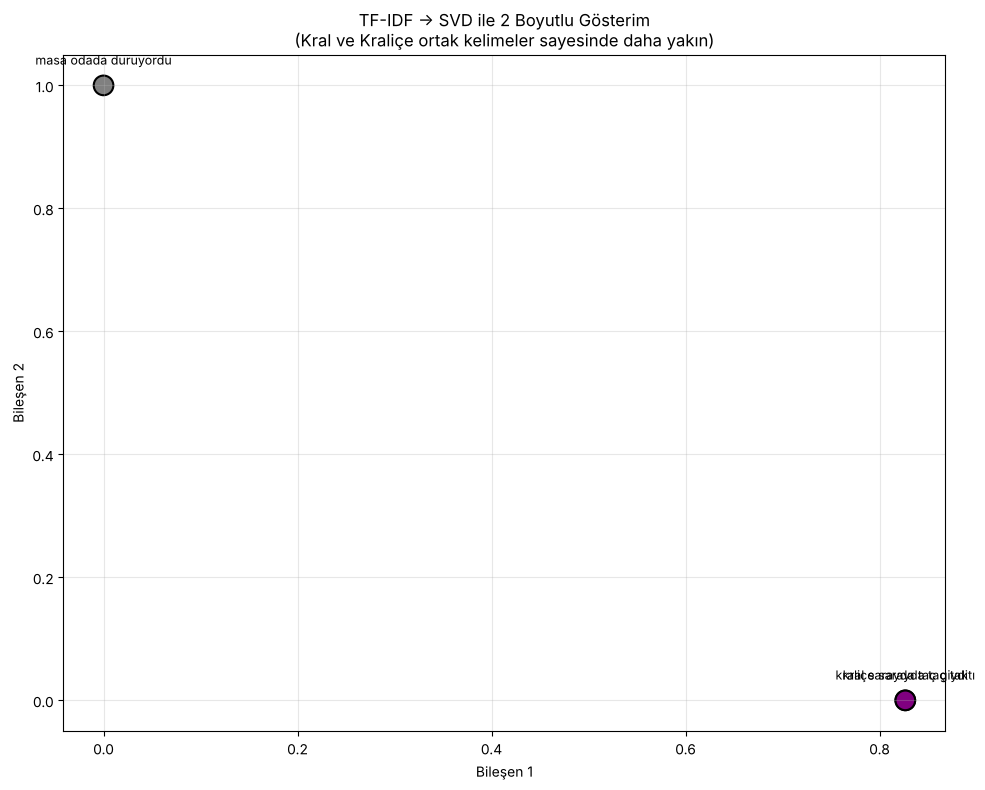

Not: Boyut indirgeme sonrası kral ve kraliçe birbirine daha yakın konumlanır.
Ancak bu sadece ortak kelimelerden kaynaklanır. Gerçek semantik anlayış
için Word2Vec veya BERT gibi modeller gereklidir.


In [26]:
# Görselleştirme: 2D düzlemde kelime konumları
plt.figure(figsize=(10, 8))

etiketler = ["kral sarayda taç giydi", "kraliçe sarayda taç taktı", "masa odada duruyordu"]
renkler = ['gold', 'purple', 'gray']

plt.scatter(m_dense[:, 0], m_dense[:, 1], c=renkler, s=200, edgecolors='black', linewidth=1.5)
for i, label in enumerate(etiketler):
    plt.annotate(f"{label}", (m_dense[i, 0], m_dense[i, 1]),
                 textcoords="offset points", xytext=(0, 15), ha='center', fontsize=9)

plt.title("TF-IDF → SVD ile 2 Boyutlu Gösterim\n(Kral ve Kraliçe ortak kelimeler sayesinde daha yakın)")
plt.xlabel("Bileşen 1")
plt.ylabel("Bileşen 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Not: Boyut indirgeme sonrası kral ve kraliçe birbirine daha yakın konumlanır.")
print("Ancak bu sadece ortak kelimelerden kaynaklanır. Gerçek semantik anlayış")
print("için Word2Vec veya BERT gibi modeller gereklidir.")